# 3.3 — Relaciones entre variables por visualización

**Aspecto del rúbrica:** *Relaciones entre variables por visualización*.

Esta libreta busca, con gráficas, cómo se relacionan los casos de infecciones
respiratorias agudas (IRA) en Hermosillo con el clima y el aire. Responde cuatro
preguntas:

1. ¿En qué meses suben los casos y en qué meses cambia cada variable?
2. Cuando dos variables parecen relacionadas, ¿lo están de verdad o solo
   coinciden en la época del año?
3. Comparando semanas de la **misma época**, ¿hay más casos cuando hace más frío
   de lo normal, hay más humedad o el aire está peor?
4. ¿El efecto se nota en las semanas siguientes?

Antecede a `3.4-correlacion`, que mide estas relaciones con números.

## Resumen

- **La época del año explica casi todo (Parte A).** Solo con saber en qué mes
  estamos se explica el **79 %** de lo que suben y bajan los casos, que casi se
  triplican de julio a enero. Muchas relaciones que se ven a simple vista son
  coincidencias de calendario: tal cual, cada grado más de temperatura va con
  ~195 casos menos por semana, pero comparando con lo normal para su mes la
  diferencia es de apenas 5 casos.
- **Quitando la época, solo queda una señal pequeña (Parte B):** después de
  semanas con más frío de lo normal hay unos **3 % más casos** en las semanas
  siguientes que después de semanas con más calor. Es la única que pasa la
  prueba del azar; la humedad, el PM10 y el ozono pueden ser casualidad.
- **Pero no se repite todos los años:** la señal del frío es fuerte en 2018 y
  2019 y casi nula en 2015–2017.
- **En pocas palabras:** con estos datos no se puede afirmar que el clima o el
  aire cambien los casos de IRA en Hermosillo más allá de la época del año. Lo
  que vale la pena revisar en 3.4–3.5 es el frío fuera de lo normal en las
  semanas previas.

## Entradas

| Ruta | Contenido |
|------|-----------|
| `data/processed/panel_eda_semanal.parquet` o `panel_eda.parquet` (según `GRANULARIDAD`) | Variables EDA del paso 7 de `3.0`. Se usan los valores **medidos**: los que rellenó 3.1 no se grafican, para no dibujar relaciones con datos estimados |

## Salidas
- Figuras en `reports/figures/` (`rel_*_{GRANULARIDAD}.png`).

## Checklist
- [x] Series de casos y exposición en el tiempo
- [x] Estacionalidad: tres pruebas de que los casos se mueven con la época del año
- [x] Scatter casos vs. cada exposición (coloreado por temporada)
- [x] Comparación dentro de la misma época y en las semanas siguientes
- [x] ¿Podría ser casualidad? (prueba del azar)
- [x] ¿Pasa lo mismo todos los años?
- [x] Casos con y sin sequía / ola de calor
- [x] Pairplot de las variables clave
- [x] Resumen y conclusiones; [ ] consulta con el equipo

## Configuración e imports

In [52]:
from pathlib import Path
import sys

ROOT_DIR = Path.cwd().parent.parent  # notebooks/<seccion>/ -> raiz del proyecto
if str(ROOT_DIR) not in sys.path:
    sys.path.append(str(ROOT_DIR))

from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sonora_health_climate_eda.config import FIGURES_DIR, PROCESSED_DATA_DIR

GRANULARIDAD = "semanal"  # "mensual" para la comparación

_CFG = {
    "semanal": {"archivo": "panel_eda_semanal.parquet", "fecha": "fecha_semana",
                "y": "casos_ira_total", "tmax": "tmax_media_sem",
                "ola_p95_y_sequia": "semana_ola_calor_p95_y_sequia"},
    "mensual": {"archivo": "panel_eda.parquet", "fecha": "fecha_mes",
                "y": "casos_ira_por_semana", "tmax": "tmax_media_mes",
                "ola_p95_y_sequia": "mes_ola_calor_p95_y_sequia"},
}[GRANULARIDAD]
FECHA, Y, TMAX = _CFG["fecha"], _CFG["y"], _CFG["tmax"]
PERIODO = "semana" if GRANULARIDAD == "semanal" else "mes"
PERIODOS = "semanas" if GRANULARIDAD == "semanal" else "meses"

NOMBRE = {
    Y: "Casos de IRA",
    TMAX: "Temperatura máx. (°C)",
    "humedad_rel_media": "Humedad (%)",
    "severidad_sequia": "Sequía (0 a 4)",
    "pm10_ugm3": "PM10 (µg/m³)",
    "o3_max8h_ppb": "Ozono (ppb)",
}
VARIABLES = [TMAX, "humedad_rel_media", "pm10_ugm3", "o3_max8h_ppb"]
TODAS = [Y, TMAX, "humedad_rel_media", "severidad_sequia", "pm10_ugm3", "o3_max8h_ppb"]

# 2020 fuera de las comparaciones: los casos cayeron por el cambio de registro
# en la pandemia, no por el clima (ver 3.0 y 3.2). Sí aparece en las gráficas.
EXCLUIR_2020 = True

# Temporadas del clima de Hermosillo:
#   frío (nov-feb): temperaturas más bajas y pico de casos
#   seco (mar-jun): poca humedad, ozono más alto del año
#   monzón (jul-oct): lluvias de verano, más humedad
TEMPORADAS = ["frío (nov–feb)", "seco (mar–jun)", "monzón (jul–oct)"]
TEMPORADA_POR_MES = {11: TEMPORADAS[0], 12: TEMPORADAS[0], 1: TEMPORADAS[0], 2: TEMPORADAS[0],
                     3: TEMPORADAS[1], 4: TEMPORADAS[1], 5: TEMPORADAS[1], 6: TEMPORADAS[1],
                     7: TEMPORADAS[2], 8: TEMPORADAS[2], 9: TEMPORADAS[2], 10: TEMPORADAS[2]}
MESES = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]

AZUL, AZUL_CLARO, NARANJA, AQUA = "#2a78d6", "#9ec5f4", "#eb6834", "#1baf7a"
GRIS, GRIS_CLARO, FONDO_2020 = "#52514e", "#b4b2a9", "#f0efec"
COLOR_TEMPORADA = dict(zip(TEMPORADAS, [AZUL, NARANJA, AQUA]))
AZULES = LinearSegmentedColormap.from_list(
    "azules", ["#eef4fc", "#9ec5f4", "#3987e5", "#1c5cab", "#0d366b"])
AZUL_ROJO = LinearSegmentedColormap.from_list("azul_rojo", ["#2a78d6", "#f0efec", "#e34948"])
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
                     "axes.axisbelow": True})

ruta = PROCESSED_DATA_DIR / _CFG["archivo"]
if not ruta.exists():
    raise FileNotFoundError(f"Falta {ruta.name}: completar el paso 7 de 3.0-integracion-espacial.ipynb")
panel = pd.read_parquet(ruta).sort_values(FECHA).reset_index(drop=True)
panel["anio_atipico"] = panel["anio_atipico"].astype(bool)
panel["anio"] = panel[FECHA].dt.year
panel["mes"] = panel[FECHA].dt.month
panel["temporada"] = pd.Categorical(panel["mes"].map(TEMPORADA_POR_MES),
                                    categories=TEMPORADAS, ordered=True)

# "Lo normal para su mes" = el promedio de ese mes en 2015-2019.
# Ej.: si en enero hubo en promedio 6,200 casos/semana, una semana de enero con
# 6,500 casos tuvo ~5 % más de lo normal.
referencia = panel[~panel["anio_atipico"]]


def normal_del_mes(col):
    """Promedio de la columna en el mismo mes del año (2015-2019), fila por fila."""
    return panel["mes"].map(referencia.groupby("mes")[col].mean())


panel["casos_vs_normal_pct"] = (panel[Y] - normal_del_mes(Y)) / normal_del_mes(Y) * 100
for var in VARIABLES:
    panel[f"{var}_vs_normal"] = panel[var] - normal_del_mes(var)

base = panel[~panel["anio_atipico"]].copy() if EXCLUIR_2020 else panel.copy()
print(f"Panel {GRANULARIDAD}: {len(panel)} {PERIODOS}; "
      f"para comparar se usan {len(base)} ({'2015-2019' if EXCLUIR_2020 else '2015-2020'})")


Panel semanal: 313 semanas; para comparar se usan 260 (2015-2019)


## 1. Los casos y el clima a lo largo del tiempo

Una gráfica por variable, todas con el mismo eje de tiempo, para ver si los
picos coinciden. El fondo gris es 2020 y los puntos naranjas en la temperatura
son los periodos con ola de calor.

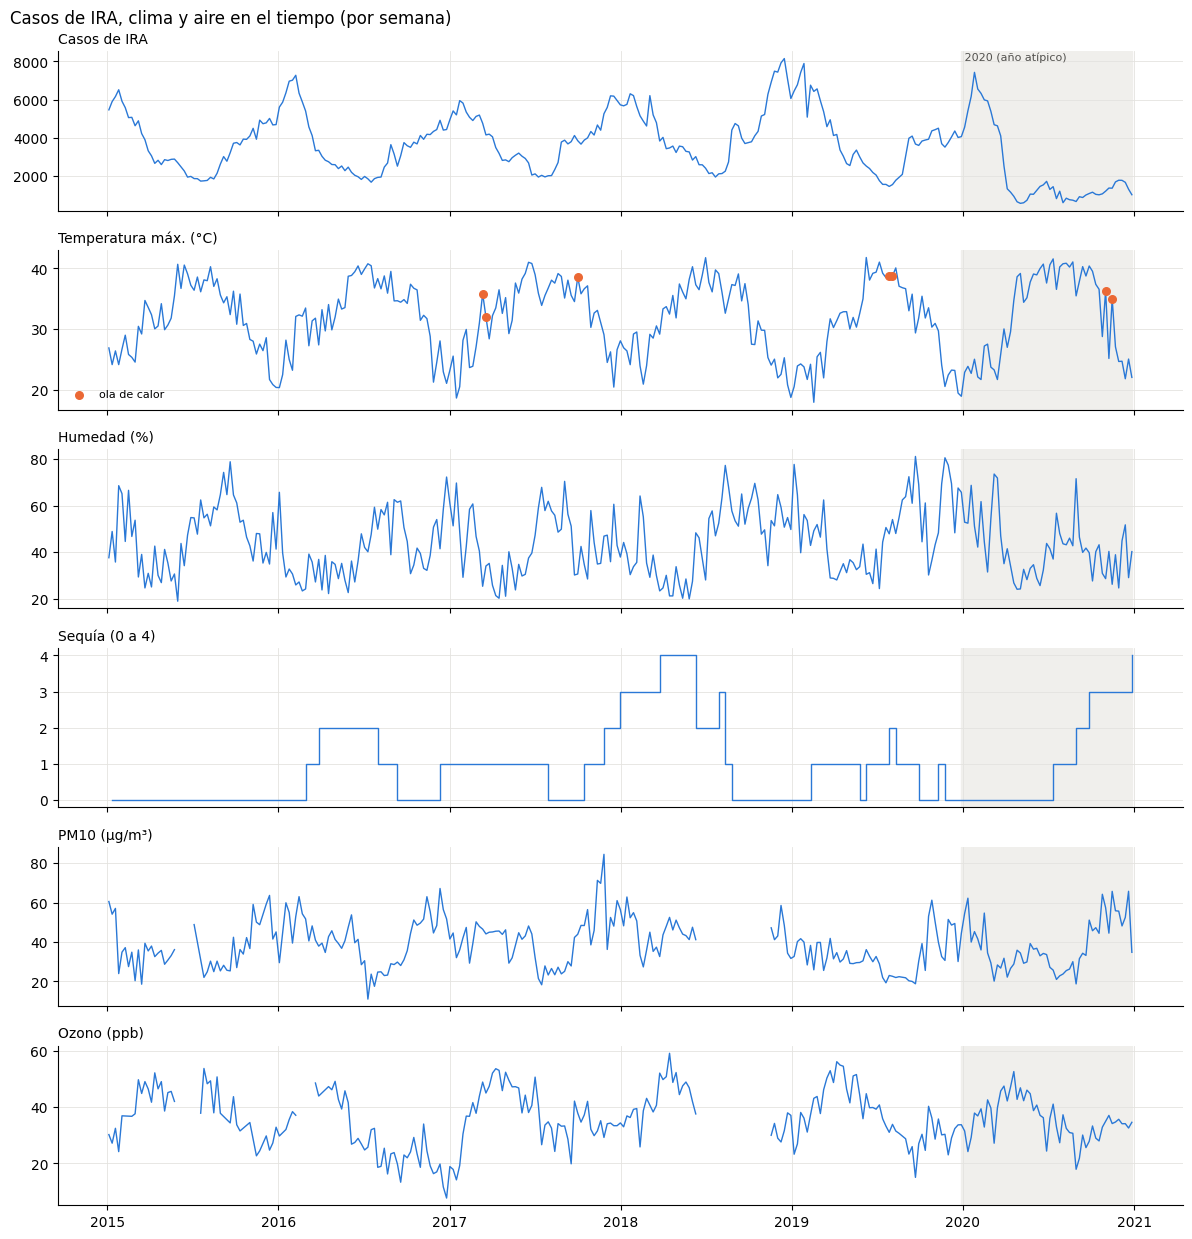

In [53]:
ola = panel["dias_ola_calor_p95"] > 0
inicio_2020, fin_2020 = panel.loc[panel["anio_atipico"], FECHA].agg(["min", "max"])

fig, axes = plt.subplots(len(TODAS), 1, figsize=(12, 2.1 * len(TODAS)), sharex=True)
for ax, col in zip(axes, TODAS):
    ax.axvspan(inicio_2020, fin_2020, color=FONDO_2020, zorder=0)
    if col == "severidad_sequia":
        ax.step(panel[FECHA], panel[col], where="post", color=AZUL, lw=1)  # en escalones
    else:
        ax.plot(panel[FECHA], panel[col], color=AZUL, lw=1)
    ax.set_title(NOMBRE[col], loc="left", fontsize=10)

axes[1].scatter(panel.loc[ola, FECHA], panel.loc[ola, TMAX], color=NARANJA, s=30, zorder=3,
                label="ola de calor")
axes[1].legend(loc="lower left", frameon=False, fontsize=8)
axes[0].text(inicio_2020, axes[0].get_ylim()[1], " 2020 (año atípico)", va="top",
             fontsize=8, color=GRIS)
fig.suptitle(f"Casos de IRA, clima y aire en el tiempo (por {PERIODO})", x=0.01, ha="left")
fig.tight_layout()
fig.savefig(FIGURES_DIR / f"rel_series_{GRANULARIDAD}.png", dpi=150)
plt.show()


## Parte A — ¿Todo se mueve con la época del año?

Esta es la idea central de la libreta: **casi todo lo que pasa con los casos de
IRA se explica por la época del año**, y muchas relaciones que se ven a simple
vista son solo eso: dos cosas que tienen su pico en la misma temporada. Las
secciones 2 a 5 lo demuestran con tres pruebas:

| Prueba | Qué se ve | Sección |
|--------|-----------|---------|
| 1. Los picos caen siempre en los mismos meses | Los casos suben en invierno y cada variable tiene su propia temporada, igual todos los años | 2 y 3 |
| 2. El mes del año explica la mayor parte de las subidas y bajadas | Solo con saber en qué mes estamos se "adivina" casi todo el movimiento de los casos | 4 |
| 3. Al quitar la época, la relación desaparece | La temperatura y el PM10 parecen muy ligados a los casos, pero dejan de estarlo al comparar semanas del mismo mes | 5 |

## 2. Prueba 1: ¿en qué meses sube cada variable?

Cada fila es una variable y cada columna un mes (promedio de 2015 a 2019). El
color va de claro (el mes más bajo de **esa** variable) a oscuro (su mes más
alto), y el número es el valor promedio. Así se ve de un vistazo en qué meses
coinciden los picos.

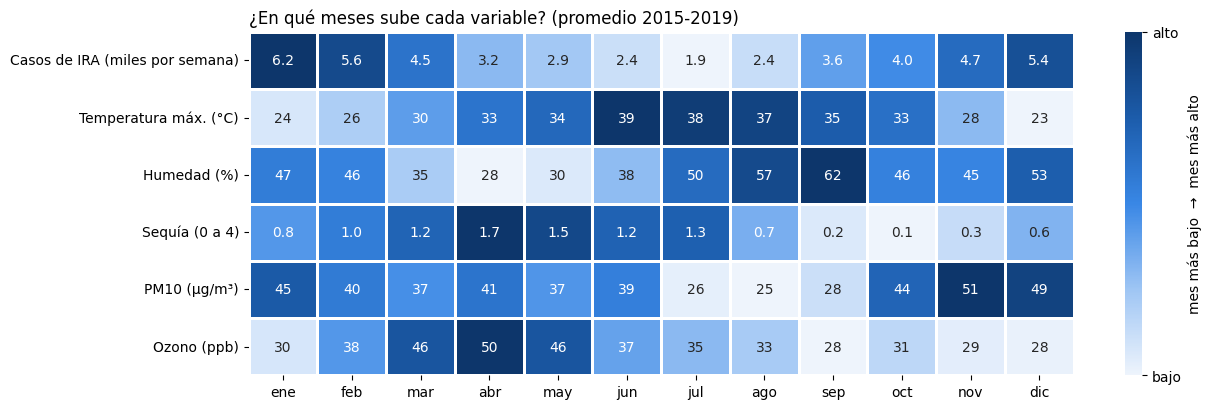

In [54]:
# color por fila: 0 = mes más bajo de esa variable, 1 = el más alto,
# así todas las filas usan la misma escala aunque tengan unidades distintas
perfil = base.groupby("mes")[TODAS].mean().T      # filas = variables, columnas = meses
escala = perfil.sub(perfil.min(axis=1), axis=0).div(perfil.max(axis=1) - perfil.min(axis=1), axis=0)

# números en cada celda: casos en miles; sequía con un decimal
texto = perfil.round(0).astype(int).astype(str)
texto.loc[Y] = (perfil.loc[Y] / 1000).map("{:.1f}".format)
texto.loc["severidad_sequia"] = perfil.loc["severidad_sequia"].map("{:.1f}".format)

etiquetas_filas = [f"{NOMBRE[c]} (miles por semana)" if c == Y else NOMBRE[c]
                   for c in perfil.index]
fig, ax = plt.subplots(figsize=(13, 4.2))
sns.heatmap(escala, annot=texto, fmt="", cmap=AZULES, linewidths=1, linecolor="white",
            cbar_kws={"label": "mes más bajo  →  mes más alto", "ticks": [0, 1]}, ax=ax)
ax.collections[0].colorbar.set_ticklabels(["bajo", "alto"])
ax.set_xticklabels(MESES, rotation=0)
ax.set_yticklabels(etiquetas_filas, rotation=0)
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_title("¿En qué meses sube cada variable? (promedio 2015-2019)", loc="left")
fig.tight_layout()
fig.savefig(FIGURES_DIR / f"rel_calendario_{GRANULARIDAD}.png", dpi=150)
plt.show()


**Los casos frente a cada variable, mes por mes.** Cada panel pone en la misma
escala la línea de los casos (azul) y la de una variable (naranja): 0 % es su
mes más bajo y 100 % su mes más alto. Si las dos líneas suben y bajan juntas,
tienen la misma temporada; si una sube cuando la otra baja, tienen temporadas
opuestas. Debajo de cada panel se indica en qué mes tiene su pico cada una.

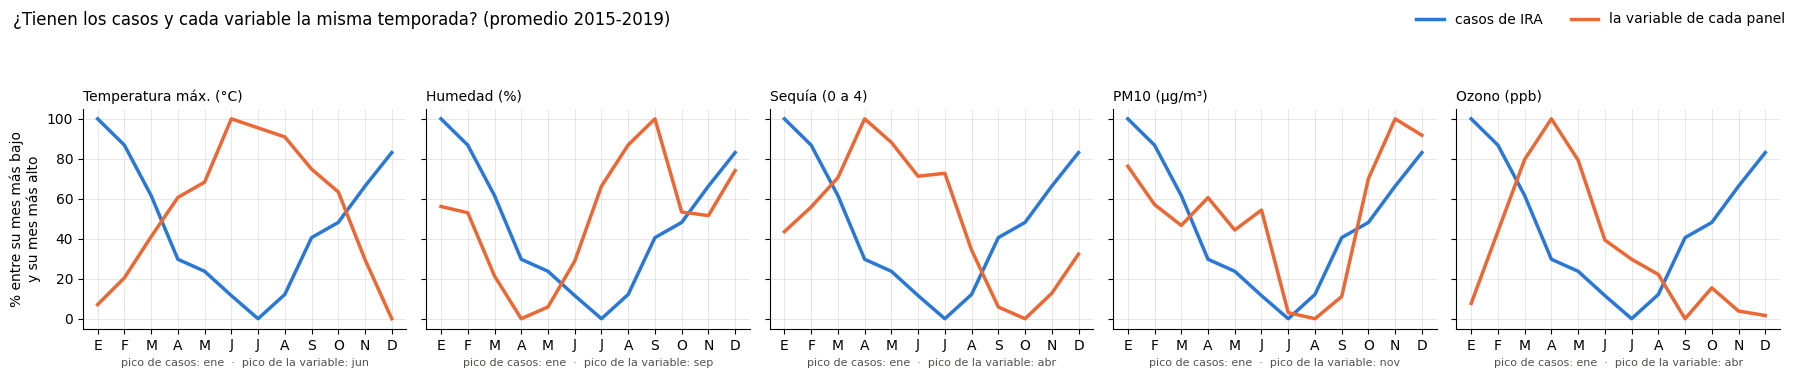

In [55]:
# 'escala' pone cada variable de 0 (su mes más bajo) a 1 (el más alto); *100 para leerlo en %
OTRAS = [TMAX, "humedad_rel_media", "severidad_sequia", "pm10_ugm3", "o3_max8h_ppb"]
fig, axes = plt.subplots(1, len(OTRAS), figsize=(18, 3.8), sharey=True)
for ax, var in zip(axes, OTRAS):
    ax.plot(range(1, 13), escala.loc[Y] * 100, color=AZUL, lw=2.5)
    ax.plot(range(1, 13), escala.loc[var] * 100, color=NARANJA, lw=2.5)
    ax.set_xticks(range(1, 13), [m[0].upper() for m in MESES])
    ax.set_title(NOMBRE[var], loc="left", fontsize=10)
    pico_casos = MESES[perfil.loc[Y].idxmax() - 1]
    pico_var = MESES[perfil.loc[var].idxmax() - 1]
    ax.set_xlabel(f"pico de casos: {pico_casos}  ·  pico de la variable: {pico_var}",
                  fontsize=8, color=GRIS)
axes[0].set_ylabel("% entre su mes más bajo\ny su mes más alto")
fig.legend(handles=[Line2D([], [], color=AZUL, lw=2.5, label="casos de IRA"),
                    Line2D([], [], color=NARANJA, lw=2.5, label="la variable de cada panel")],
           loc="upper right", ncol=2, frameon=False)
fig.suptitle("¿Tienen los casos y cada variable la misma temporada? (promedio 2015-2019)",
             x=0.01, ha="left")
fig.tight_layout(rect=(0, 0, 1, 0.9))
fig.savefig(FIGURES_DIR / f"rel_perfiles_{GRANULARIDAD}.png", dpi=150)
plt.show()


**Qué se ve (panel semanal):**

- **Temperatura:** es el espejo de los casos. Los casos tienen su pico en enero,
  cuando hace más frío, y su punto más bajo en julio, cuando hace más calor.
- **PM10:** sube y baja casi junto con los casos (alto de noviembre a enero).
- **Humedad y sequía:** tienen su propia temporada (humedad en septiembre por el
  monzón, sequía en primavera), distinta a la de los casos.
- **Ozono:** su pico es en abril, cuando los casos ya van bajando.

Por eso, si se comparan tal cual, la temperatura y el PM10 van a parecer muy
relacionados con los casos: comparten el calendario.

## 3. Prueba 1 (continuación): pasa igual todos los años

Una gráfica por variable, con **una línea por año** mes a mes: gris para cada
año de 2015 a 2019, azul para su promedio y naranja para 2020. Si los picos
fueran cosa de un solo año, las líneas grises irían cada una por su lado; aquí
se **enciman**: suben y bajan en los mismos meses año tras año. La línea naranja
muestra lo distinto que fue 2020 en los casos (pandemia). La excepción es la
**sequía**: cada año va por su lado (2018 muy seco, 2015 sin sequía), por eso el
mes explica tan poco de ella (sección 4). Los huecos en las líneas del aire son
meses sin medición (el apagón de la estación en 2018).

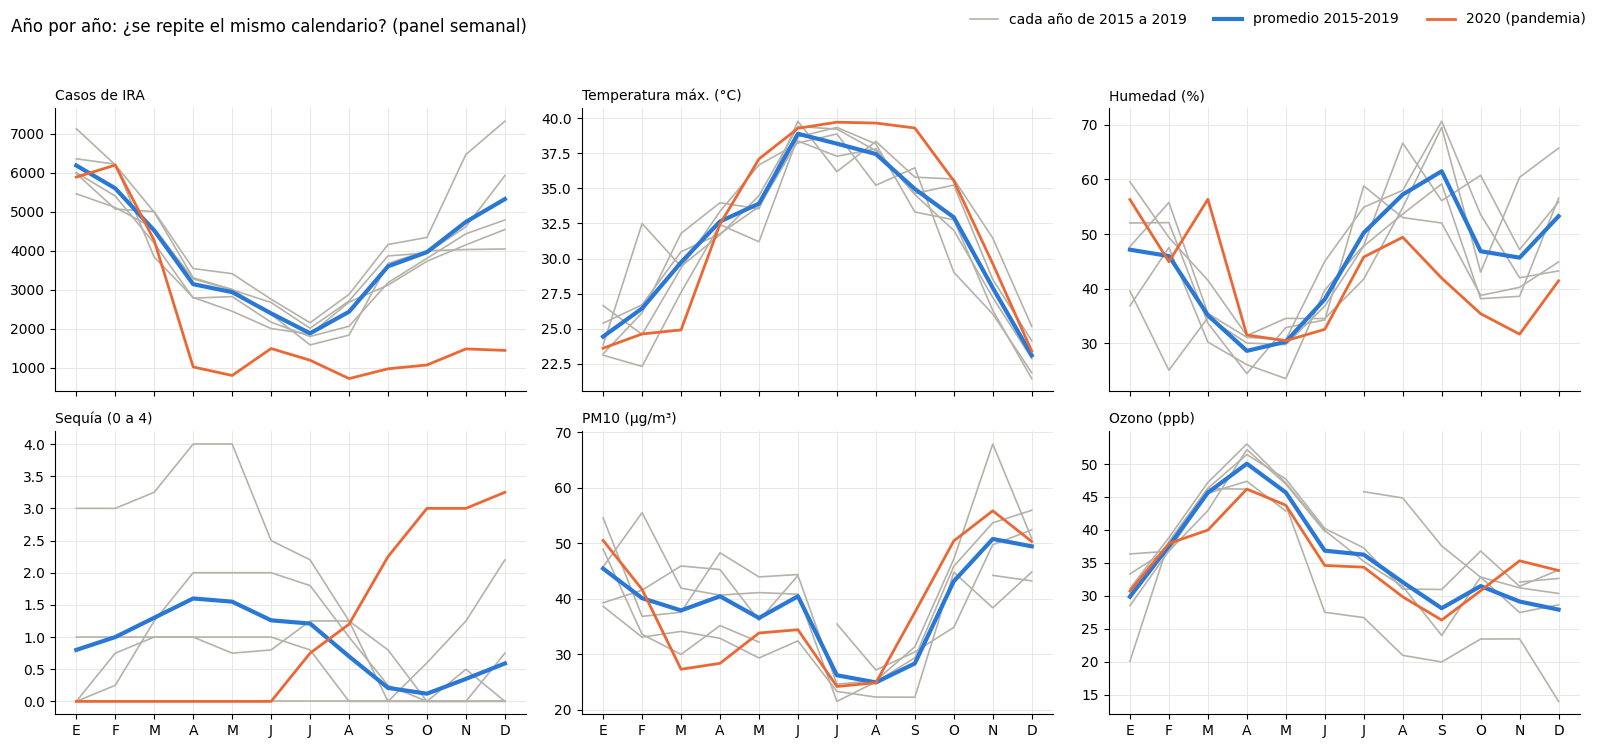

In [56]:
por_anio_mes = panel.groupby(["anio", "mes"])[TODAS].mean()
anios_atipicos = panel.groupby("anio")["anio_atipico"].mean().loc[lambda s: s > 0.5].index

fig, axes = plt.subplots(2, 3, figsize=(16, 7.5), sharex=True)
for ax, col in zip(axes.flat, TODAS):
    tabla = por_anio_mes[col].unstack("mes").reindex(columns=range(1, 13))
    for anio, fila in tabla.iterrows():
        if anio in anios_atipicos:
            ax.plot(range(1, 13), fila, color=NARANJA, lw=2, zorder=3)
        else:
            ax.plot(range(1, 13), fila, color=GRIS_CLARO, lw=1.2, zorder=1)
    normales = tabla.loc[~tabla.index.isin(anios_atipicos)]
    ax.plot(range(1, 13), normales.mean(), color=AZUL, lw=3, zorder=2)
    ax.set_xticks(range(1, 13), [m[0].upper() for m in MESES])
    ax.set_title(NOMBRE[col], loc="left", fontsize=10)
fig.legend(handles=[Line2D([], [], color=GRIS_CLARO, lw=1.2, label="cada año de 2015 a 2019"),
                    Line2D([], [], color=AZUL, lw=3, label="promedio 2015-2019"),
                    Line2D([], [], color=NARANJA, lw=2, label="2020 (pandemia)")],
           loc="upper right", ncol=3, frameon=False)
fig.suptitle(f"Año por año: ¿se repite el mismo calendario? (panel {GRANULARIDAD})",
             x=0.01, ha="left")
fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.savefig(FIGURES_DIR / f"rel_anio_mes_{GRANULARIDAD}.png", dpi=150)
plt.show()


## 4. Prueba 2: ¿cuánto depende cada variable del mes del año?

Una forma sencilla de medirlo: si de cada semana solo supiéramos **en qué mes
estamos**, y usáramos el promedio de ese mes como "adivinanza", ¿qué parte de
las subidas y bajadas acertaríamos?

- **100 %**: el mes lo explica todo; la variable hace lo mismo cada año.
- **0 %**: el mes no dice nada; la variable sube y baja sin importar la época.

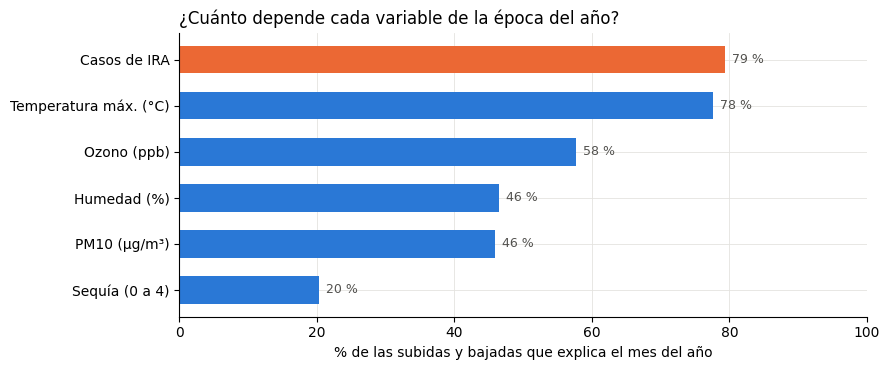

In [57]:
# qué parte de la variación de cada variable se explica solo con el mes:
# cada periodo se "adivina" con el promedio de su mes y se mide
# 1 - (variación de lo no adivinado) / (variación total)
explicado = {}
for col in TODAS:
    datos = base[[col, "mes"]].dropna()
    no_adivinado = datos[col] - datos.groupby("mes")[col].transform("mean")
    explicado[NOMBRE[col]] = 100 * (1 - no_adivinado.var() / datos[col].var())
explicado = pd.Series(explicado).sort_values()

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh(explicado.index, explicado,
        color=[NARANJA if nombre == NOMBRE[Y] else AZUL for nombre in explicado.index],
        height=0.6)
for i, valor in enumerate(explicado):
    ax.text(valor + 1, i, f"{valor:.0f} %", va="center", fontsize=9, color=GRIS)
ax.set_xlim(0, 100)
ax.set_xlabel("% de las subidas y bajadas que explica el mes del año")
ax.set_title("¿Cuánto depende cada variable de la época del año?", loc="left")
fig.tight_layout()
fig.savefig(FIGURES_DIR / f"rel_depende_del_mes_{GRANULARIDAD}.png", dpi=150)
plt.show()


**Qué se ve (panel semanal):** solo con saber el mes se explica el **79 %** de
lo que suben y bajan los casos, y el 78 % de la temperatura. El ozono depende
del mes en un 58 %, la humedad y el PM10 en un 46 %, y la sequía apenas en un
20 % (depende más del año que del mes: 2018 fue muy seco). Es decir, los casos
son sobre todo un fenómeno de temporada: lo que queda para que el clima o el
aire expliquen es, como mucho, el 21 % restante.

## 5. Prueba 3: al quitar la época, ¿se mantiene la relación?

Si dos cosas solo coinciden en la época del año, su relación debería
**desaparecer** al comparar semanas del mismo mes.

Primero, tal cual. Cada punto es un periodo y el color es su temporada. Fíjate
en que cada temporada forma **su propia nube**: las semanas de frío (azul)
están arriba, con muchos casos; las de monzón (verde), abajo. La relación que
se ve entre todos los puntos sale de comparar invierno contra verano.

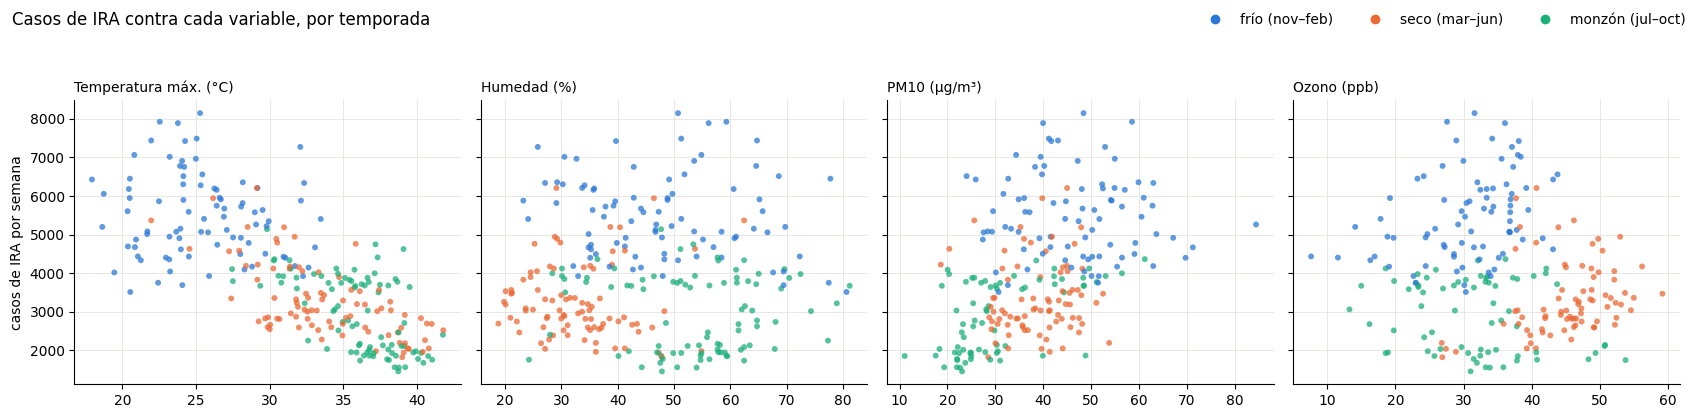

In [58]:
fig, axes = plt.subplots(1, len(VARIABLES), figsize=(17, 4.2), sharey=True)
for ax, var in zip(axes, VARIABLES):
    sns.scatterplot(data=base, x=var, y=Y, hue="temporada", hue_order=TEMPORADAS,
                    palette=COLOR_TEMPORADA, ax=ax, s=18, alpha=0.75, edgecolor="none",
                    legend=False)
    ax.set_title(NOMBRE[var], loc="left", fontsize=10)
    ax.set_xlabel("")
axes[0].set_ylabel("casos de IRA por semana")
fig.legend(handles=[Line2D([], [], marker="o", lw=0, color=COLOR_TEMPORADA[t], label=t)
                    for t in TEMPORADAS],
           loc="upper right", ncol=3, frameon=False)
fig.suptitle("Casos de IRA contra cada variable, por temporada", x=0.01, ha="left")
fig.tight_layout(rect=(0, 0, 1, 0.93))
fig.savefig(FIGURES_DIR / f"rel_scatter_{GRANULARIDAD}.png", dpi=150)
plt.show()


**El ejemplo de la temperatura, antes y después.** A la izquierda, tal cual:
mientras más calor, muchos menos casos. A la derecha, cada semana comparada con
**lo normal para su mes**: cuántos grados más calurosa o más fría fue, y cuántos
casos de más o de menos tuvo. Si la línea de la derecha queda plana, la relación
de la izquierda era solo de temporada.

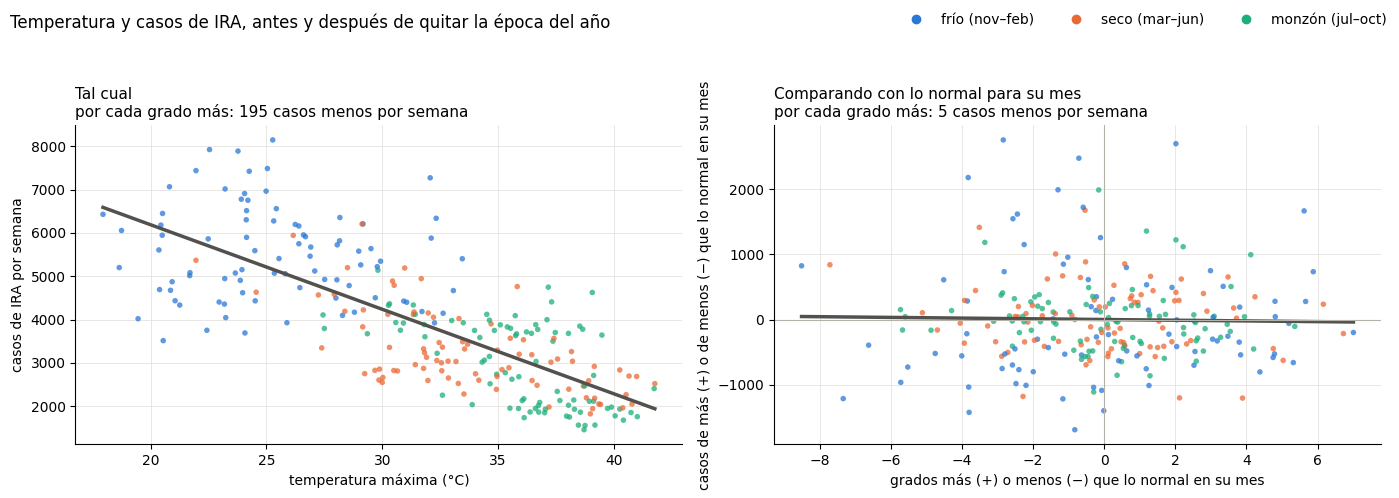

In [59]:
datos = base[[TMAX, Y, "mes", "temporada"]].dropna()
colores = datos["temporada"].astype(str).map(COLOR_TEMPORADA)
vistas = [
    ("Tal cual", datos[TMAX], datos[Y],
     "temperatura máxima (°C)", "casos de IRA por semana"),
    ("Comparando con lo normal para su mes",
     datos[TMAX] - datos.groupby("mes")[TMAX].transform("mean"),
     datos[Y] - datos.groupby("mes")[Y].transform("mean"),
     "grados más (+) o menos (−) que lo normal en su mes",
     "casos de más (+) o de menos (−) que lo normal en su mes"),
]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (titulo, x, y, etiqueta_x, etiqueta_y) in zip(axes, vistas):
    ax.scatter(x, y, c=colores, s=16, alpha=0.75, edgecolors="none")
    pendiente, ordenada = np.polyfit(x, y, 1)
    xs = np.linspace(x.min(), x.max(), 50)
    ax.plot(xs, pendiente * xs + ordenada, color=GRIS, lw=2.5)
    ax.set_title(f"{titulo}\npor cada grado más: {abs(pendiente):,.0f} casos "
                 f"{'más' if pendiente > 0 else 'menos'} por semana", loc="left", fontsize=11)
    ax.set_xlabel(etiqueta_x)
    ax.set_ylabel(etiqueta_y)
axes[1].axhline(0, color=GRIS_CLARO, lw=0.8)
axes[1].axvline(0, color=GRIS_CLARO, lw=0.8)
fig.legend(handles=[Line2D([], [], marker="o", lw=0, color=COLOR_TEMPORADA[t], label=t)
                    for t in TEMPORADAS],
           loc="upper right", ncol=3, frameon=False)
fig.suptitle("Temperatura y casos de IRA, antes y después de quitar la época del año",
             x=0.01, ha="left")
fig.tight_layout(rect=(0, 0, 1, 0.93))
fig.savefig(FIGURES_DIR / f"rel_antes_despues_{GRANULARIDAD}.png", dpi=150)
plt.show()


**Lo mismo para cada variable:** cuántos casos de IRA por semana cambian por
cada unidad más de la variable, tal cual y comparando con lo normal para su mes.

In [60]:
UNIDAD = {TMAX: "°C", "humedad_rel_media": "punto de humedad",
          "pm10_ugm3": "µg/m³ de PM10", "o3_max8h_ppb": "ppb de ozono"}
filas = []
for var in VARIABLES:
    datos = base[[var, Y, "mes"]].dropna()
    tal_cual = np.polyfit(datos[var], datos[Y], 1)[0]
    mismo_mes = np.polyfit(datos[var] - datos.groupby("mes")[var].transform("mean"),
                           datos[Y] - datos.groupby("mes")[Y].transform("mean"), 1)[0]
    filas.append({"variable": NOMBRE[var], "por cada": f"1 {UNIDAD[var]} más",
                  "tal cual": f"{tal_cual:+,.0f} casos",
                  "comparando con su mes": f"{mismo_mes:+,.0f} casos"})
pd.DataFrame(filas).set_index("variable")


,por cada,tal cual,comparando con su mes
variable,,,
Temperatura máx. (°C),1 °C más,-195 casos,-5 casos
Humedad (%),1 punto de humedad más,+2 casos,-8 casos
PM10 (µg/m³),1 µg/m³ de PM10 más,+58 casos,+7 casos
Ozono (ppb),1 ppb de ozono más,-25 casos,+20 casos


**Qué se ve (panel semanal):**

- **Temperatura:** tal cual, cada grado más va con **~195 casos menos** por
  semana; comparando con su mes, apenas **5**. La relación desaparece: era la
  temporada (invierno frío con muchos casos, verano caluroso con pocos).
- **PM10:** pasa de +58 a +7 casos: también era sobre todo la temporada.
- **Ozono:** pasa lo contrario. Tal cual parece que más ozono va con **menos**
  casos (−25), pero comparando con su mes va con **más** casos (+20). La época
  también puede esconder una relación: el ozono tiene su pico en primavera,
  cuando los casos ya van bajando.
- **Humedad:** no hay una relación clara ni antes ni después (+2 y −8 casos).

**Conclusión de la Parte A:** las relaciones fuertes que se ven tal cual son,
sobre todo, de temporada. Para saber si el clima o el aire influyen de verdad
hay que comparar periodos de la misma época, que es lo que hace la Parte B.

## Parte B — Quitando la época del año, ¿queda alguna relación?

De aquí en adelante, cada periodo se compara con **lo normal para su mes** (el
promedio de ese mes en 2015–2019), para que la temporada ya no influya. La
pregunta es sencilla: **¿qué pasa con los casos en las semanas que siguen a una
semana más fría (o más húmeda, o más contaminada) de lo normal?**

## 6. ¿Qué pasa con los casos después de un periodo fuera de lo normal?

Para cada variable, los periodos se separan en **dos grupos**: los que
estuvieron por **debajo** de lo normal para su mes (por ejemplo, semanas con más
frío de lo normal) y los que estuvieron por **encima** (semanas con más calor).
Luego se mira cuántos casos hubo, comparado con lo normal, esa misma semana y
en las 8 semanas siguientes.

**Cómo leerlo:** cada gráfica tiene dos líneas.

- Si las dos líneas van **juntas**, esa variable no cambia los casos.
- Si se **separan**, sí: la línea que va arriba es el grupo con más casos.

Por ejemplo, en la temperatura: si la línea azul (después de semanas con más
frío) va arriba de la naranja (después de semanas con más calor), después del
frío hay más casos.

In [61]:
# cada variable separa los periodos en dos grupos: por debajo o por encima de lo
# normal para su mes; se mide cuántos casos (vs. lo normal) hubo 0, 1, 2... periodos después
DESPUES = list(range(0, 9)) if GRANULARIDAD == "semanal" else list(range(0, 4))
en_base = ~panel["anio_atipico"] if EXCLUIR_2020 else pd.Series(True, index=panel.index)
casos_pct = panel["casos_vs_normal_pct"].where(en_base)  # 2020 queda vacío

GRUPOS = {
    TMAX: ("más frío de lo normal", "más calor de lo normal"),
    "humedad_rel_media": ("menos humedad de lo normal", "más humedad de lo normal"),
    "pm10_ugm3": ("menos PM10 de lo normal", "más PM10 de lo normal"),
    "o3_max8h_ppb": ("menos ozono de lo normal", "más ozono de lo normal"),
}
debajo = {v: en_base & (panel[f"{v}_vs_normal"] < 0) for v in VARIABLES}
encima = {v: en_base & (panel[f"{v}_vs_normal"] > 0) for v in VARIABLES}


def casos_despues(casos, filas=en_base):
    """Para cada variable, casos (vs. lo normal) 0, 1, 2... periodos después de los
    periodos de cada grupo: (línea del grupo 'debajo', línea del grupo 'encima').

    .shift(-k) "adelanta" la serie: en la fila del periodo t queda el valor de t+k.
    """
    futuros = {k: casos.shift(-k) for k in DESPUES}
    return {
        v: (np.array([futuros[k][debajo[v] & filas].mean() for k in DESPUES]),
            np.array([futuros[k][encima[v] & filas].mean() for k in DESPUES]))
        for v in VARIABLES
    }


def diferencia_promedio(lineas):
    """Qué tanto se separan las dos líneas en promedio (grupo 'encima' menos 'debajo')."""
    return pd.Series({NOMBRE[v]: np.nanmean(arriba - abajo)
                      for v, (abajo, arriba) in lineas.items()})


lineas = casos_despues(casos_pct)
diferencia = diferencia_promedio(lineas)


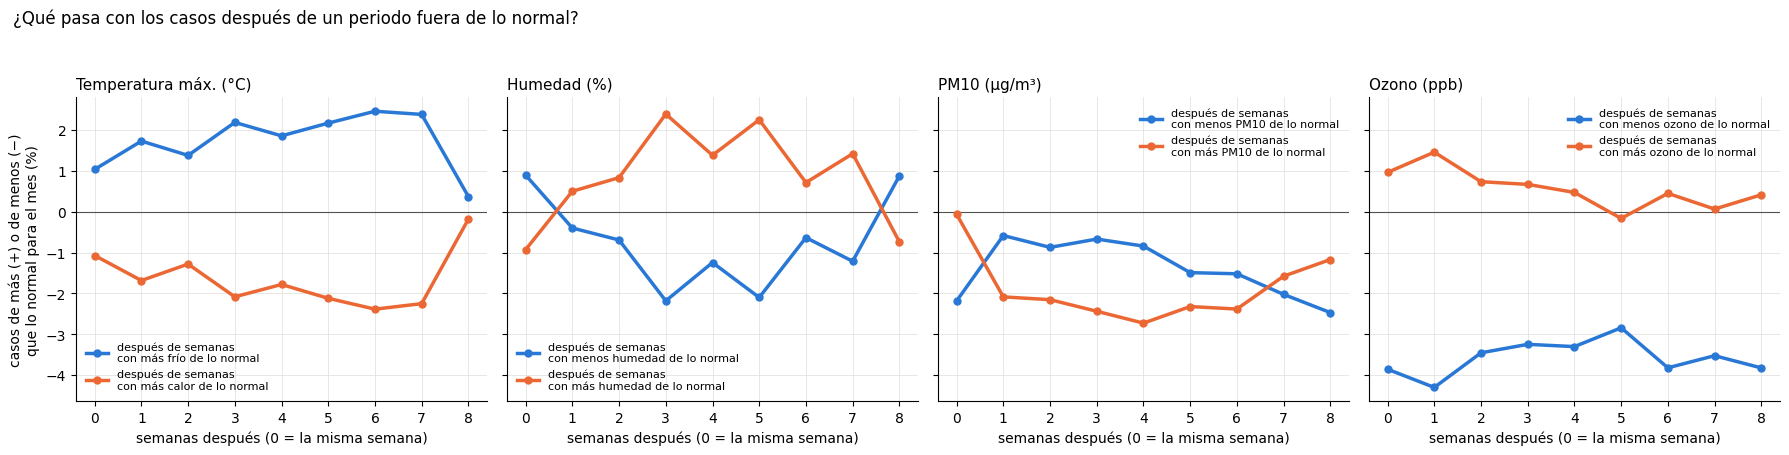

In [62]:
cero = "la misma semana" if GRANULARIDAD == "semanal" else "el mismo mes"
fig, axes = plt.subplots(1, len(VARIABLES), figsize=(18, 4.6), sharey=True)
for ax, var in zip(axes, VARIABLES):
    abajo, arriba = lineas[var]
    texto_abajo, texto_arriba = GRUPOS[var]
    ax.axhline(0, color=GRIS, lw=0.8)
    ax.plot(DESPUES, abajo, color=AZUL, lw=2.5, marker="o", ms=5,
            label=f"después de {PERIODOS}\ncon {texto_abajo}")
    ax.plot(DESPUES, arriba, color=NARANJA, lw=2.5, marker="o", ms=5,
            label=f"después de {PERIODOS}\ncon {texto_arriba}")
    ax.set_xticks(DESPUES)
    ax.set_xlabel(f"{PERIODOS} después (0 = {cero})")
    ax.set_title(NOMBRE[var], loc="left", fontsize=11)
    ax.legend(loc="best", fontsize=8, frameon=False)
axes[0].set_ylabel("casos de más (+) o de menos (−)\nque lo normal para el mes (%)")
fig.suptitle("¿Qué pasa con los casos después de un periodo fuera de lo normal?",
             x=0.01, ha="left")
fig.tight_layout(rect=(0, 0, 1, 0.94))
fig.savefig(FIGURES_DIR / f"rel_despues_{GRANULARIDAD}.png", dpi=150)
plt.show()


**Qué se ve (panel semanal):**

- **Temperatura:** las líneas se separan durante casi todas las semanas.
  Después de semanas con más frío de lo normal (azul) hay unos 2 % más casos de
  lo normal; después de semanas con más calor (naranja), unos 2 % menos.
- **Ozono:** después de semanas con menos ozono de lo normal los casos quedan
  por debajo de lo normal (−3 a −4 %); después de semanas con más ozono, cerca
  de lo normal.
- **Humedad y PM10:** las líneas van casi juntas o se cruzan: no hay una
  diferencia clara.

## 7. ¿Podría ser casualidad?

Aunque el clima no tuviera nada que ver, las dos líneas nunca quedarían
exactamente juntas: siempre hay diferencias por azar. Para saber cuánto puede
separarlas el puro azar, se **revuelven los casos al azar** 1,000 veces y se
repite la comparación. Se revuelven en bloques de 8 semanas (2 meses en el
panel mensual), para no romper el parecido que hay entre semanas vecinas.

La tabla compara la separación real con la que da el azar:

- **Poco probable:** el azar separó las líneas igual o más menos de 50 veces
  de 1,000. Es difícil que sea casualidad.
- **En el límite:** entre 50 y 100 veces de 1,000.
- **Sí, puede ser:** más de 100 veces de 1,000.

In [63]:
# prueba del azar: se revuelven los casos 1,000 veces (en bloques de periodos
# seguidos, para no romper la autocorrelación) y se mide cuánto se separan las
# líneas solo por azar
BLOQUE = 8 if GRANULARIDAD == "semanal" else 2
N_BARAJADAS = 1000
rng = np.random.default_rng(42)
posiciones = np.flatnonzero(en_base.to_numpy())
bloques = [posiciones[i:i + BLOQUE] for i in range(0, len(posiciones), BLOQUE)]
valores = casos_pct.to_numpy()

azar = []
for _ in range(N_BARAJADAS):
    orden = rng.permutation(len(bloques))
    revueltos = casos_pct.copy()
    revueltos.iloc[posiciones] = np.concatenate([valores[bloques[i]] for i in orden])
    azar.append(diferencia_promedio(casos_despues(revueltos)))
azar = pd.DataFrame(azar)

# cuántas barajadas separaron las líneas tanto o más que la realidad
centro = azar.mean()
veces = (azar.sub(centro).abs() >= (diferencia - centro).abs()).sum()


def veredicto(n):
    """Traduce el número de veces a palabras."""
    if n < 50:
        return "poco probable"
    if n <= 100:
        return "en el límite"
    return "sí, puede ser"


pd.DataFrame({
    "se compara": [f"{GRUPOS[v][1]} vs. {GRUPOS[v][0]}" for v in VARIABLES],
    "diferencia en casos": diferencia.map("{:+.1f} %".format).to_numpy(),
    "veces que el azar dio algo igual o mayor (de 1,000)": veces.astype(int).to_numpy(),
    "¿puede ser casualidad?": veces.map(veredicto).to_numpy(),
}, index=diferencia.index)


,se compara,diferencia en casos,"veces que el azar dio algo igual o mayor (de 1,000)",¿puede ser casualidad?
Temperatura máx. (°C),más calor de lo normal vs. más frío de lo normal,-3.4 %,26,poco probable
Humedad (%),más humedad de lo normal vs. menos humedad de ...,+1.6 %,397,"sí, puede ser"
PM10 (µg/m³),más PM10 de lo normal vs. menos PM10 de lo normal,-0.5 %,881,"sí, puede ser"
Ozono (ppb),más ozono de lo normal vs. menos ozono de lo n...,+4.1 %,122,"sí, puede ser"


**Cómo leer la tabla:** la "diferencia en casos" es qué tanto se separan, en
promedio, las dos líneas de la sección 6. Negativa = después de periodos con
**más** de la variable hubo **menos** casos. Por ejemplo, −3.4 % en la
temperatura quiere decir que después de semanas con más calor de lo normal hubo,
en promedio, 3.4 % menos casos que después de semanas con más frío.

**Qué se ve (panel semanal):** solo la **temperatura** pasa la prueba: el azar
separó las líneas tanto como en la realidad apenas 26 veces de 1,000. El ozono
(122 de 1,000), la humedad (397) y el PM10 (881) pueden ser casualidad. En el
panel mensual ninguna variable pasa la prueba.

## 8. ¿Pasa lo mismo todos los años?

Si una relación es real, debería verse en casi todos los años, no solo en uno.
Cada barra es un año: la diferencia de la sección 7, pero calculada solo con
las semanas de ese año. La línea punteada es el resultado de todos los años
juntos.

**Cómo leerlo:** barras hacia abajo (azul) = después de periodos con más de la
variable hubo menos casos; hacia arriba (naranja) = hubo más. **Si todas las
barras van del mismo lado, el patrón es sólido**; si unas van arriba y otras
abajo, depende del año.

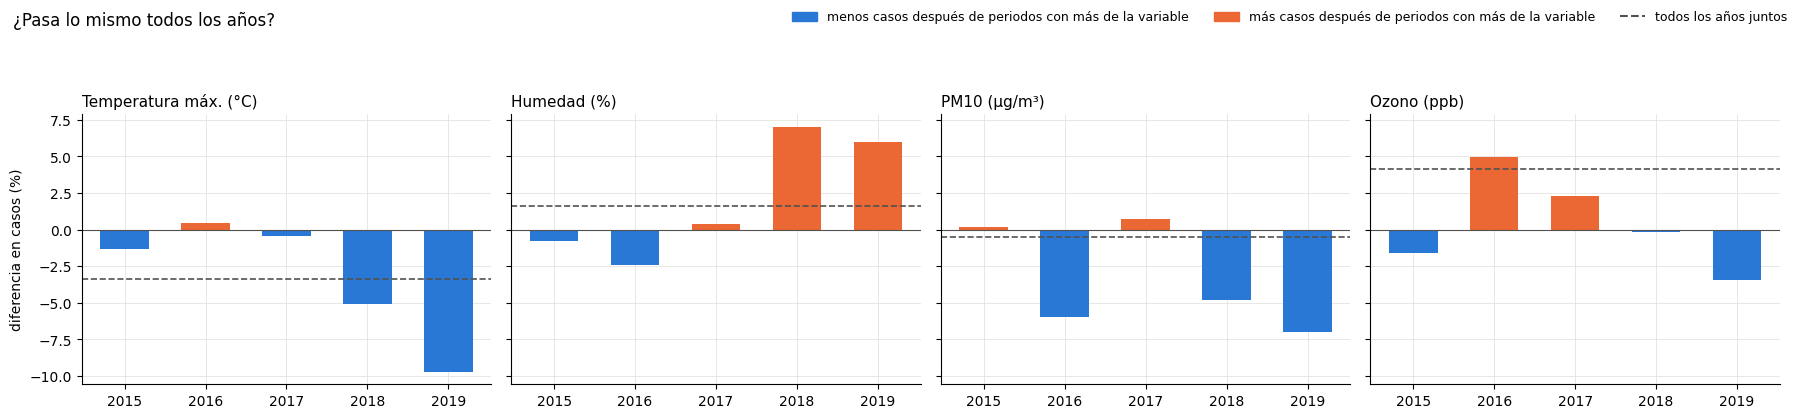

In [64]:
anios = sorted(panel.loc[en_base, "anio"].unique())
por_anio = pd.DataFrame({
    a: diferencia_promedio(casos_despues(casos_pct, en_base & (panel["anio"] == a)))
    for a in anios
})  # filas = variables, columnas = años

fig, axes = plt.subplots(1, len(VARIABLES), figsize=(18, 4.2), sharey=True)
for ax, var in zip(axes, por_anio.index):
    valores_anio = por_anio.loc[var]
    ax.bar([str(a) for a in anios], valores_anio, width=0.6,
           color=[NARANJA if v > 0 else AZUL for v in valores_anio])
    ax.axhline(diferencia[var], color=GRIS, ls="--", lw=1.2)
    ax.axhline(0, color=GRIS, lw=0.8)
    ax.set_title(var, loc="left", fontsize=11)
axes[0].set_ylabel("diferencia en casos (%)")
fig.legend(handles=[Patch(color=AZUL, label="menos casos después de periodos con más de la variable"),
                    Patch(color=NARANJA, label="más casos después de periodos con más de la variable"),
                    Line2D([], [], color=GRIS, ls="--", label="todos los años juntos")],
           loc="upper right", ncol=3, frameon=False, fontsize=9)
fig.suptitle("¿Pasa lo mismo todos los años?", x=0.01, ha="left")
fig.tight_layout(rect=(0, 0, 1, 0.9))
fig.savefig(FIGURES_DIR / f"rel_por_anio_{GRANULARIDAD}.png", dpi=150)
plt.show()


**Qué se ve (panel semanal):** en la **temperatura** casi todas las barras van
hacia abajo, pero la diferencia es grande solo en 2018 (−5 %) y 2019 (−10 %); en
2015–2017 es casi cero. En la humedad, 2018 y 2019 van hacia arriba y los otros
años hacia abajo; en el ozono y el PM10 los años no coinciden. Es decir, incluso
la señal de la temperatura depende sobre todo de dos años.

## 9. Sequía y olas de calor

A la izquierda, el promedio de casos tal cual; a la derecha, comparado con lo
normal para el mes. Si una barra cambia mucho de una gráfica a la otra, la
diferencia de la izquierda venía de la época del año y no de la sequía.

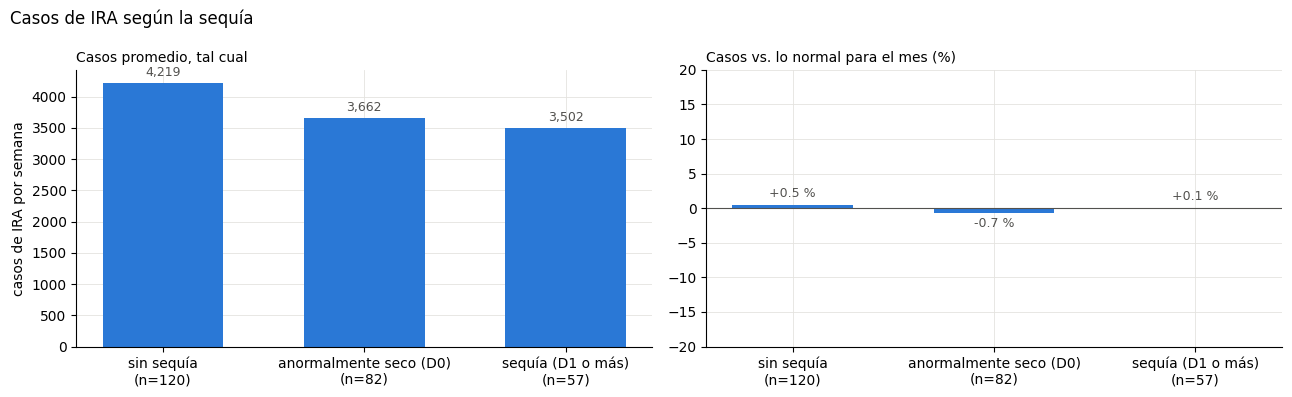

Semanas con ola de calor (2015-2019): 5 de 260; casos vs. lo normal: -13.0 %
Con ola de calor y sequía a la vez: 1


,periodos,casos_promedio,casos_vs_normal_pct
sequia_cat,,,
sin sequía,120,4218.5,0.5
anormalmente seco (D0),82,3662.3,-0.7
sequía (D1 o más),57,3502.3,0.1


In [65]:
# escala de severidad (config.DROUGHT_SEVERITY_MAP): 0 = sin sequía, 1 = D0,
# 2 = D1 (moderada), 3 = D2 (severa), 4 = D3 (extrema)
CATEGORIAS_SEQUIA = ["sin sequía", "anormalmente seco (D0)", "sequía (D1 o más)"]
base["sequia_cat"] = pd.cut(base["severidad_sequia"], [-0.5, 0.5, 1.5, 9],
                            labels=CATEGORIAS_SEQUIA)
resumen_sequia = base.groupby("sequia_cat", observed=True).agg(
    periodos=(Y, "size"), casos_promedio=(Y, "mean"), casos_vs_normal_pct=("casos_vs_normal_pct", "mean"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
etiquetas = [f"{c}\n(n={n})" for c, n in zip(resumen_sequia.index, resumen_sequia["periodos"])]
axes[0].bar(etiquetas, resumen_sequia["casos_promedio"], color=AZUL, width=0.6)
axes[0].set_title("Casos promedio, tal cual", loc="left", fontsize=10)
axes[0].set_ylabel("casos de IRA por semana")
axes[1].bar(etiquetas, resumen_sequia["casos_vs_normal_pct"], color=AZUL, width=0.6)
axes[1].axhline(0, color=GRIS, lw=0.8)
axes[1].set_ylim(-20, 20)
axes[1].set_title("Casos vs. lo normal para el mes (%)", loc="left", fontsize=10)
for ax, columna, formato in [(axes[0], "casos_promedio", "{:,.0f}"),
                             (axes[1], "casos_vs_normal_pct", "{:+.1f} %")]:
    for x, valor in enumerate(resumen_sequia[columna]):
        ax.annotate(formato.format(valor), (x, valor), ha="center",
                    va="bottom" if valor >= 0 else "top", xytext=(0, 3 if valor >= 0 else -3),
                    textcoords="offset points", fontsize=9, color=GRIS)
fig.suptitle("Casos de IRA según la sequía", x=0.01, ha="left")
fig.tight_layout()
fig.savefig(FIGURES_DIR / f"rel_sequia_{GRANULARIDAD}.png", dpi=150)
plt.show()

# olas de calor: son tan pocas que solo se cuentan
con_ola = base["dias_ola_calor_p95"] > 0
print(f"{PERIODOS.capitalize()} con ola de calor (2015-2019): {con_ola.sum()} de {len(base)}; "
      f"casos vs. lo normal: {base.loc[con_ola, 'casos_vs_normal_pct'].mean():+.1f} %")
print(f"Con ola de calor y sequía a la vez: {int(base[_CFG['ola_p95_y_sequia']].sum())}")
resumen_sequia.round(1)


## 10. Todas las variables a la vez (pairplot)

Cada cuadro cruza dos variables y cada punto es un periodo, coloreado por
temporada. En la diagonal está cómo se reparten los valores de cada variable en
cada temporada. Sirve para ver todas las parejas juntas.

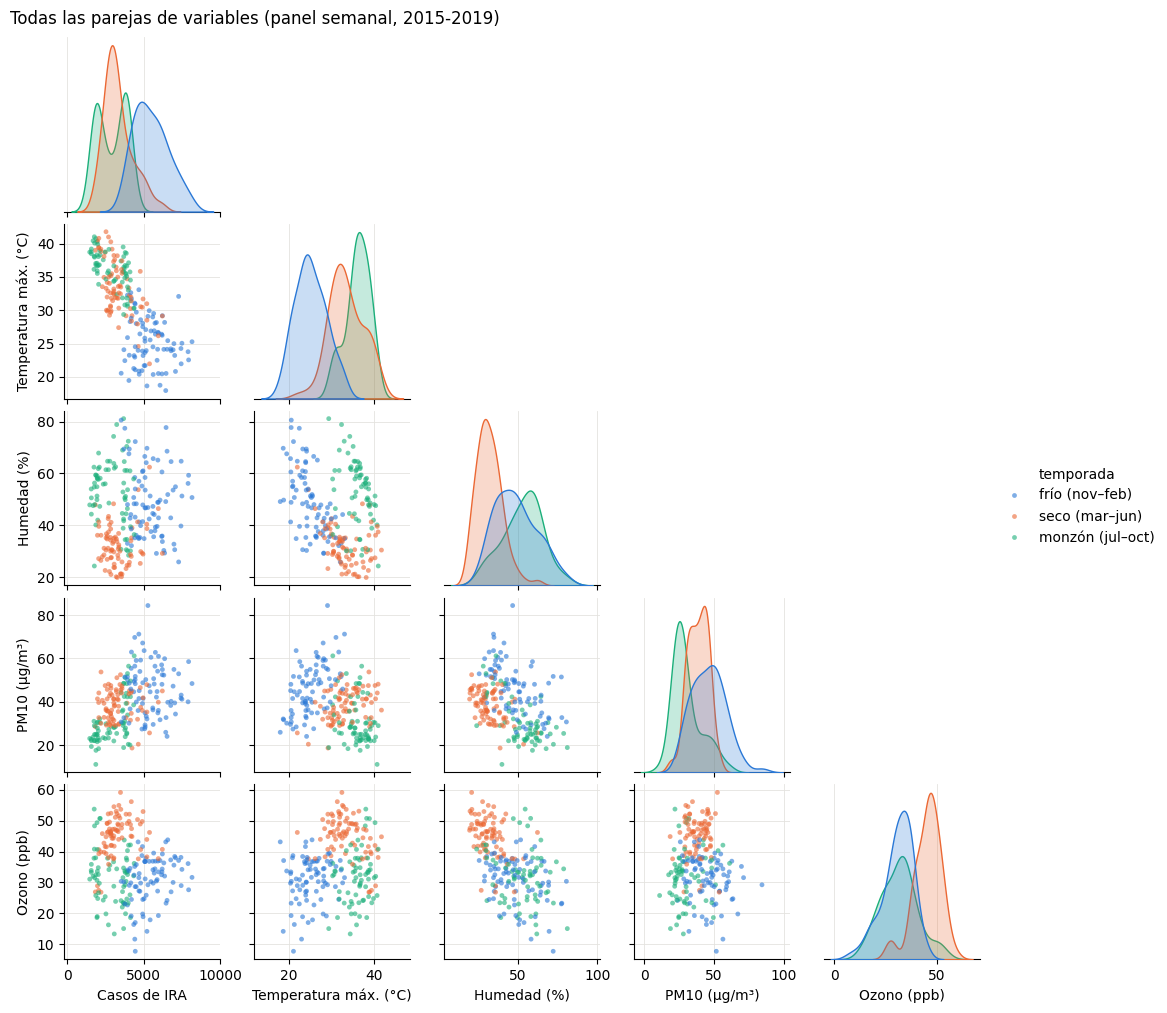

In [66]:
cols_pair = [Y, *VARIABLES]
datos_pair = base[cols_pair + ["temporada"]].dropna().rename(columns=NOMBRE)
g = sns.pairplot(datos_pair, hue="temporada", hue_order=TEMPORADAS, palette=COLOR_TEMPORADA,
                 corner=True, diag_kind="kde", height=2.0,
                 plot_kws={"s": 12, "alpha": 0.6, "edgecolor": "none"})
g.figure.suptitle(f"Todas las parejas de variables (panel {GRANULARIDAD}, 2015-2019)",
                  x=0.01, ha="left", y=1.01)
g.savefig(FIGURES_DIR / f"rel_pairplot_{GRANULARIDAD}.png", dpi=150)
plt.show()


## Conclusiones

Lo que muestran las gráficas del **panel semanal** (2015–2019), en palabras sencillas:

**1. La época del año es lo que más pesa (Parte A).** Lo demuestran tres
pruebas:

- **Los picos caen siempre en los mismos meses** (secciones 2 y 3): los casos
  casi se triplican de julio (~1,900 por semana) a enero (~6,200), y eso se
  repite todos los años. Cada variable tiene su propio calendario: la
  temperatura sube en junio–agosto, la humedad en septiembre (monzón), el ozono
  en abril, el PM10 en noviembre–diciembre y la sequía en primavera.
- **El mes del año explica la mayor parte** (sección 4): solo con saber el mes
  se explica el 79 % de lo que suben y bajan los casos y el 78 % de la
  temperatura.
- **Al quitar la época, la relación desaparece** (sección 5): tal cual, cada
  grado más de temperatura va con ~195 casos menos por semana; comparando
  semanas del mismo mes, apenas 5. El PM10 pasa de +58 a +7 casos por µg/m³.

**2. Muchas "relaciones" son solo coincidencias de calendario.** En invierno
hace frío, hay más PM10 y más casos al mismo tiempo, pero eso no prueba que el
frío o el PM10 causen los casos. La sequía es otro ejemplo: tal cual, las
semanas con sequía tienen 17 % menos casos (3,502 contra 4,219 por semana), pero
comparadas con lo normal para su mes la diferencia es prácticamente cero
(+0.1 %); la sequía cae en primavera, cuando hay menos casos de todos modos. Y
la época también puede **esconder** una relación: tal cual, más ozono parece ir
con menos casos, pero dentro del mismo mes va con más casos.

**3. Quitando la época, solo la temperatura deja una señal (Parte B).** Después
de semanas con más frío de lo normal para su mes hay, en las 8 semanas
siguientes, unos 2 % más casos de lo normal; después de semanas con más calor,
unos 2 % menos. La diferencia entre los dos grupos (3.4 %) es pequeña, pero el
azar casi nunca la produce: solo 26 veces de 1,000 (sección 7).

**4. Las demás variables no dejan una señal clara.** El ozono va con unos 4 %
más casos, pero el azar da diferencias así con frecuencia (122 de 1,000); la
humedad (397) y el PM10 (881), todavía menos.

**5. La señal de la temperatura no se repite todos los años** (sección 8): es
fuerte en 2018 y 2019 y casi nula en 2015–2017. Una posible explicación, no
comprobada: en esos años la temporada de IRA y el frío llegaron antes o después
de lo normal al mismo tiempo, y con estos datos eso no se puede separar de un
efecto del frío.

**6. Año por año** se ven además tres cosas: 2020 se cae desde abril (de 700 a
1,500 casos por semana, por la pandemia); 2018 tuvo la sequía más intensa (D3
en primavera) y la temporada de IRA más fuerte a fin de año (7,300 casos por
semana en diciembre); y en 2016 el ozono estuvo bajo casi todo el segundo
semestre (el valor dudoso que marcó 3.2).

**7. Olas de calor:** solo hubo 5 semanas con ola de calor en 2015–2019 (y 1 con
ola de calor y sequía a la vez). Son muy pocas para sacar conclusiones.

En el **panel mensual** ninguna variable pasa la prueba del azar: con 60 meses es
más difícil distinguir diferencias tan pequeñas.

**Qué llevar a 3.4 y 3.5:**

- Medir las relaciones comparando con lo normal para cada mes, no con los
  valores tal cual; si no, la época del año domina todo.
- Probar la temperatura de las semanas previas (el frío fuera de lo normal),
  sin esperar efectos grandes.
- Revisar por qué 2018 y 2019 se comportan distinto (¿se adelantó la temporada
  de IRA?) y el ozono sin el segundo semestre de 2016.
- No usar las olas de calor como variable: hay muy pocas.
- Considerar casos por cada 100 mil habitantes y por grupo de edad: podrían
  mostrar señales que el total diluye.